# SFT обучение ассистента по домашним растениям — полный пайплайн в одном ноутбуке

Дообучаем `Qwen/Qwen2.5-3B-Instruct` отвечать на вопросы по уходу за комнатными
растениями на русском языке.

**Как запустить:**
1. `Среда выполнения → Сменить среду выполнения → T4 GPU`
2. `Среда выполнения → Выполнить всё`

Ноутбук самодостаточен: проверки, seed-данные и eval-вопросы встроены в ячейки.
Промежуточные результаты сохраняются на диск — при обрыве сессии повторный запуск
продолжится с места обрыва.

**Пайплайн:** автопроверки → данные → бейзлайн → синтетическое расширение данных
(deepseek-v4-flash, API) → QLoRA-обучение → оценка до/после (автопроверки +
слепой LLM-судья yandexgpt, API).

Для генерации данных и судейства нужен API-ключ Yandex Cloud — ноутбук запросит
его в скрытом поле (или задайте переменную окружения `LLM_API_KEY`).

Суммарное время на T4: ~1–1,5 часа.

In [2]:
!pip install -q -U trl peft bitsandbytes datasets accelerate transformers openai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
litellm 1.93.2 requires openai<3.0.0,>=2.20.0, but you have openai 3.45.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [3]:
!python -c "import transformers, trl, peft; print('transformers', transformers.__version__, '| trl', trl.__version__, '| peft', peft.__version__)"

transformers 5.22.1 | trl 1.17.1 | peft 0.21.2


In [4]:
import torch

assert torch.cuda.is_available(), (
    "Нужен GPU: Среда выполнения → Сменить среду выполнения → T4 GPU, затем "
    "Среда выполнения → Выполнить всё"
)
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 1. Автоматические проверки ответов

Критерии и их обоснование для темы:

| Проверка | Правило | Почему важно |
|---|---|---|
| `language` | доля кириллицы среди букв ≥ 0.5 | вопросы русскоязычные; при дообучении модели «уезжают» в английский; порог < 1, т.к. латинские видовые названия (Phalaenopsis) легитимны |
| `list_format` | ≥ 2 пунктов списка | для инструкций по уходу список — основной читаемый формат |
| `no_repetition` | нет дублей строк/предложений, 5-словные шинглы ≤ 2 | типовая деградация SFT на малых данных — зацикливание |
| `length` | 150–2500 символов | пустой ответ бесполезен, «простыня» не читается |

In [5]:
# -*- coding: utf-8 -*-
"""Автоматические проверки ответов ассистента по теме «Домашние растения».

Критерии и их обоснование для нашей темы:

1. Язык — русский. Пользователь задаёт вопросы по-русски; instruct-модели
   при дообучении на смешанных данных нередко «переключаются» на английский.
   Порог — доля кириллицы среди букв ≥ 0.5 (в ответах легитимно встречаются
   латинские названия растений, например Phalaenopsis).

2. Формат — рекомендации списком. Для темы «уход за растениями» ответ
   из сплошного текста плохо читается: пользователь сканирует глазами
   пункты («полив», «свет», «пересадка»). Требуем ≥ 2 пунктов списка.

3. Отсутствие повторений. Типовая деградация при SFT на маленьком
   датасете — зацикливание («Поливайте умеренно. Поливайте умеренно...»).
   Ловим повторы строк, предложений и 5-словных шинглов.

4. Длина — 150…2500 символов. Пустой или односложный ответ бесполезен,
   «простыня» на 5000 символов не читается.

Использование:
    python checks.py answers.jsonl          # проверить файл
    python checks.py answers.jsonl --key answer   # если поле называется не "answer"
"""

import argparse
import json
import re
import sys
from collections import Counter

CYRILLIC_RE = re.compile(r"[а-яё]", re.IGNORECASE)
LATIN_RE = re.compile(r"[a-z]", re.IGNORECASE)
LIST_ITEM_RE = re.compile(r"^\s*(?:[-*•–]|\d+[.)])\s+\S", re.MULTILINE)
SENTENCE_SPLIT_RE = re.compile(r"[.!?]+")
SHINGLE_SIZE = 5

MIN_LEN, MAX_LEN = 150, 2500
MIN_LIST_ITEMS = 2
MAX_DUP_SENTENCES = 0
MAX_SHINGLE_REPEATS = 2


def _letters(text: str) -> str:
    return "".join(CYRILLIC_RE.findall(text) + LATIN_RE.findall(text))


def check_language(answer: str) -> bool:
    """Доля кириллицы среди букв ≥ 0.5 и букв хотя бы 20."""
    letters = _letters(answer)
    if len(letters) < 20:
        return False
    cyr = len(CYRILLIC_RE.findall(answer))
    return cyr / len(letters) >= 0.5


def check_list_format(answer: str) -> bool:
    """В ответе есть список рекомендаций (≥ 2 пунктов)."""
    return len(LIST_ITEM_RE.findall(answer)) >= MIN_LIST_ITEMS


def check_no_repetition(answer: str) -> bool:
    """Нет повторяющихся строк/предложений и зацикленных фраз."""
    # 1) одинаковые непустые строки
    lines = [ln.strip().lower() for ln in answer.splitlines() if len(ln.strip()) >= 10]
    if any(c > 1 for c in Counter(lines).values()):
        return False
    # 2) одинаковые предложения
    sentences = [s.strip().lower() for s in SENTENCE_SPLIT_RE.split(answer) if len(s.strip()) >= 10]
    if sum(c - 1 for c in Counter(sentences).values() if c > 1) > MAX_DUP_SENTENCES:
        return False
    # 3) повторяющиеся 5-словные шинглы (ловит «хвост-зацикливание»)
    words = re.findall(r"[а-яёa-z]+", answer.lower())
    shingles = Counter(tuple(words[i:i + SHINGLE_SIZE]) for i in range(len(words) - SHINGLE_SIZE + 1))
    return all(c <= MAX_SHINGLE_REPEATS for c in shingles.values())


def check_length(answer: str) -> bool:
    return MIN_LEN <= len(answer.strip()) <= MAX_LEN


CHECKS = {
    "language": check_language,
    "list_format": check_list_format,
    "no_repetition": check_no_repetition,
    "length": check_length,
}


def check_answer(answer: str) -> dict:
    """Возвращает словарь {проверка: bool} + агрегированный вердикт."""
    result = {name: fn(answer) for name, fn in CHECKS.items()}
    result["passed"] = all(result.values())
    return result


def check_file(path: str, key: str = "answer") -> dict:
    """Проверяет jsonl-файл; возвращает сводку по каждой проверке и по записям."""
    per_check = {name: 0 for name in CHECKS}
    total = 0
    failures = []
    with open(path, encoding="utf-8") as f:
        for i, line in enumerate(f):
            line = line.strip()
            if not line:
                continue
            rec = json.loads(line)
            answer = rec[key] if key in rec else rec.get("messages", [{}])[-1].get("content", "")
            res = check_answer(answer)
            total += 1
            for name in CHECKS:
                per_check[name] += res[name]
            if not res["passed"]:
                failures.append((i, [k for k in CHECKS if not res[k]]))
    return {"total": total, "per_check": per_check, "failures": failures}

print("Проверки определены:", ", ".join(CHECKS))

Проверки определены: language, list_format, no_repetition, length


In [6]:

# Примеры срабатывания каждого критерия (для отчёта)
DEMO = {
    "английский ответ": ("Water your ficus once a week in winter, letting the top layer of soil dry out "
                        "between waterings.\n- Use room temperature water only\n- Reduce feeding until spring\n"
                        "- Keep it away from cold drafts and radiators"),
    "нет списка": ("Зимой фикус поливают заметно реже, примерно раз в семь-десять дней. "
                   "Ориентируйтесь на просыхание верхнего слоя грунта на несколько сантиметров. "
                   "Воду используйте отстоянную, холодную из-под крана растение переносит плохо. "
                   "Лишнюю воду из поддона обязательно сливайте через полчаса после полива. "
                   "Перелив в холодный период опаснее недолива: корни загнивают в сырой земле."),
    "зацикливание": "Уход за фикусом:\n- поливайте умеренно\n- поливайте умеренно\n- светлое место\n\nПоливайте умеренно, поливайте умеренно, поливайте умеренно и поливайте умеренно. " + "х " * 50,
    "слишком короткий": "Ухаживайте так:\n- полив редкий\n- света побольше",
    "корректный (проходит всё)": "Зимой фикус поливают заметно реже:\n- дайте грунту просохнуть на 3–4 см;\n- поливайте раз в 7–10 дней;\n- воду используйте отстоянную.\n\nПерелив зимой опаснее недолива: в холодной сырой земле корни загнивают.",
}

print(f"{'пример':<28} {'language':<9} {'list':<6} {'no_rep':<7} {'length':<7} passed")
for name, ans in DEMO.items():
    r = check_answer(ans)
    print(f"{name:<28} {str(r['language']):<9} {str(r['list_format']):<6} "
          f"{str(r['no_repetition']):<7} {str(r['length']):<7} {r['passed']}")

пример                       language  list   no_rep  length  passed
английский ответ             False     True   True    True    False
нет списка                   True      False  True    True    False
зацикливание                 True      True   False   True    False
слишком короткий             True      True   True    False   False
корректный (проходит всё)    True      True   True    True    True


## 2. Данные: seed-датасет и отложенные вопросы

Seed (41 пример) написан вручную: полив, свет, пересадка, грунт, удобрения, влажность,
вредители, болезни, размножение, цветение, безопасность для животных, сезонный уход.
Каждый ответ соответствует целевому формату и проходит автопроверки (проверяется ниже).

Eval-набор — 15 отложенных вопросов, не пересекающихся с обучающими.

In [7]:
QA = [('Как часто поливать фикус Бенджамина зимой?', 'Зимой фикус Бенджамина поливают заметно реже, чем летом:\n- дайте верхнему слою грунта просохнуть на 3–4 см вглубь;\n- в среднем это раз в 7–10 дней при комнатной температуре;\n- воду используйте отстоянную, комнатной температуры;\n- лишнюю воду из поддона сливайте через 15–20 минут.\n\nЗимой рост замедляется, и перелив опаснее недолива: в холодной сырой земле корни легко загнивают. Если сомневаетесь — лучше подождите день-два лишний, фикус это перенесёт спокойно.'), ('Почему у монстеры желтеют листья и что делать?', 'Пожелтение листьев у монстеры чаще всего связано с ошибками полива или света:\n- желтеют нижние листья, мягкие на ощупь — перелив; дайте грунту просохнуть и сократите полив;\n- листья бледно-жёлтые, вытягиваются — мало света, переставьте ближе к окну;\n- желтеют и опадают зимой на сквозняке или у холодного окна — уберите от холода;\n- светлые сухие пятна — солнечный ожог, притените от прямого солнца.\n\nОбрежьте полностью пожелтевший лист — он уже не восстановится, а растение тратит на него ресурсы.'), ('Как реанимировать залитую орхидею фаленопсис?', 'Если фаленопсис залили (корни коричневые, мягкие, листья вялые), действуйте так:\n- достаньте растение из горшка и освободите корни от старого субстрата;\n- удалите гнилые корни до здоровой ткани стерильными ножницами;\n- присыпьте срезы толчёным углём или корицей и подсушите 2–3 часа;\n- посадите в свежий субстрат из крупной коры, закрепите в горшке.\n\nПоливать после пересадки не нужно 5–7 дней. Если здоровых корней почти не осталось, можно поставить орхидею в тепличку или на влажный мох до отрастания новых корней.'), ('Какие неприхотливые растения подойдут для северного окна?', 'Для северного окна без прямого солнца подойдёт немало растений:\n- сансевиерия (щучий хвост) — переносит и тень, и редкий полив;\n- замиокулькас — терпим к слабому свету и засухе;\n- спатифиллум — спокойно живёт на рассеянном свету;\n- аглаонема и сциндапсус — красивая листва в полутени;\n- аспидистра — недаром её называют «чугунным цветком».\n\nДаже теневыносливым растениям зимой может понадобиться досветка, если окна совсем тёмные.'), ('Как избавиться от паутинного клеща на комнатных растениях?', 'Паутинный клещ — мелкий вредитель, заметный по паутинке и светлым точкам на листьях. План борьбы:\n- изолируйте заражённое растение от остальных;\n- промойте листья и стебли тёплой водой с мыльным раствором;\n- обработайте акарицидом (клещ не насекомое, обычные инсектициды слабо работают) 2–3 раза с интервалом 5–7 дней;\n- повысьте влажность воздуха — клещ активно размножается в сухости.\n\nОсмотрите соседние растения: на ранней стадии клеща проще всего победить. Профилактика — регулярный душ для листьев.'), ('На листьях появились бугорки и липкие пятна, похоже на щитовку. Как бороться?', 'Щитовку узнают по коричневым восковым бугоркам на листьях и стеблях и липким выделениям:\n- механически снимите вредителей ватным диском, смоченным в мыльно-спиртовом растворе;\n- обработайте растение системным инсектицидом дважды с интервалом 7–10 дней;\n- протрите подоконник и вымойте горшок — личицы прячутся рядом;\n- проверьте все растения в квартире.\n\nОднократной обработки мало: из оставшихся яиц выведутся новые особи. Контрольный осмотр проведите через 2 недели.'), ('Почему у спатифиллума чернеют кончики листьев?', 'Чернеющие кончики у спатифиллума — классический сигнал стресса. Возможные причины:\n- сухой воздух, особенно зимой у батареи — чаще опрыскивайте или поставьте увлажнитель;\n- избыток или недостаток влаги: следите, чтобы между поливами верхний слой просыхал;\n- ожог корней удобрениями — промойте грунт чистой водой и сделайте паузу в подкормках;\n- холодная вода для полива — используйте отстоянную, комнатной температуры.\n\nСухие кончики можно аккуратно подрезать до живой ткани острыми ножницами, это не вредит растению.'), ('Как правильно пересадить замиокулькас?', 'Замиокулькас не любит просторные горшки и частых пересадок, поэтому:\n- выбирайте новый горшок лишь на 2–3 см шире старого, лучше тесноватый;\n- грунт нужен рыхлый: готовый для суккулентов с добавлением перлита;\n- обязательно сделайте дренажный слой 3–4 см из керамзита;\n- пересаживайте перевалкой, стараясь не разрушать земляной ком;\n- после пересадки не поливайте 3–4 дня и не ставьте на солнце.\n\nКорни у замиокульказа хрупкие и сочные, ломаются легко — не трогайте их без необходимости.'), ('Какие комнатные растения безопасны для кошек?', 'Если в доме кошка, выбирайте неядовитые растения:\n- трава для кошек (овёс, ячмень) — заодно отвлечёт от других горшков;\n- калатея и маранта — полностью безопасны;\n- пеперомия, хойя, сенполия (фиалка) — не токсичны;\n- аспарагус, традесканция, хлорофитум — безопасны и легко размножаются.\n\nОпасны для кошек: лилии, монстера, фикусы, замиокулькас, сансевиерия, цикламен, азалия. Даже неядовитое растение лучше подвесить или поставить повыше: объеденные листья страдают сами по себе.'), ('Как укоренить черенок хойи?', 'Хойя укореняется охотно, если соблюдать простые правила:\n- срежьте черенок с 2–3 узлами и парой листьев;\n- подсушите срез 1–2 часа, чтобы выступил сок;\n- укореняйте в воде, во влажном перлите или сфагнуме;\n- держите в тепле (22–25 °C) при ярком рассеянном свете;\n- ждите корни 3–6 недель, в воде виден их рост.\n\nСажайте в маленький горшочек с рыхлым субстратом, когда корни отрастут на 3–5 см. Не обрывайте цветоносы после цветения — хойя цветёт на них повторно.'), ('Почему не цветёт антуриум и как заставить его цвести?', 'Антуриум не цветёт, если не выдержаны условия:\n- света должно быть много, но без прямого солнца — восточное окно идеально;\n- зимой нужен период относительного покоя: +16…18 °C и редкий полив 1,5–2 месяца;\n- подкармливайте весной и летом удобрением с высоким содержанием фосфора;\n- горшок не должен быть слишком большим — антуриум цветёт «в тесноте»;\n- корни должны участвовать в воздухообмене: субстрат с корой и перлитом.\n\nКомфортная влажность и отсутствие сквозняков — базовые условия, без которых остальные ухищрения не сработают.'), ('Как организовать досвечивание растений фитолампой зимой?', 'Зимой светового дня растениям не хватает, досветка компенсирует дефицит:\n- выбирайте полноспектровые LED-фитолампы, биколорные (красный + синий) — базовый вариант;\n- мощность ориентируйте ~20–30 Вт на полку 60×30 см;\n- расстояние до листьев 25–40 см: ближе — ожог, дальше — слабый эффект;\n- включайте на 12–14 часов, таймер сильно упрощает жизнь;\n- повесьте отражающий экран из фольги, чтобы свет не терялся.\n\nПризнак нехватки света — вытягивание побегов и бледные мелкие листья. Суккулентам и цветущим нужно больше света, чем лиственным.'), ('Какая земля нужна суккулентам?', 'Главное в грунте для суккулентов — воздухопроницаемость и быстрое просыхание:\n- основа — готовый грунт для суккулентов и кактусов;\n- добавьте 30–50% разрыхлителей: перлит, крупный песок, цеолит;\n- небольшая доля торфа допустима, но не более трети смеси;\n- дренажный слой керамзита на дне горшка обязателен;\n- pH близкий к нейтральному, без лишней органики.\n\nПроверка простая: после полива вода должна выходить из дренажных отверстий за секунды, а грунт просыхать за пару дней.'), ('Уезжаю в отпуск на две недели. Как обеспечить растениям полив?', 'На две недели растения можно оставить без помощника, если подготовиться:\n- обильно полейте все растения перед отъездом и уберите с яркого солнца;\n- сгруппируйте горшки в поддоне с влажным керамзитом или мхом;\n- накройте землю у влаголюбивых растений мокрой газетой или сфагнумом;\n- используйте колбы-автопоилки для капризных растений;\n- суккуленты и замиокулькас спокойно выдержат 2 недели вообще без полива.\n\nДольше двух недель — уже нужна либо система капельного полива, либо помощник с инструкцией.'), ('Почему у калатеи скручиваются листья?', 'Скрученные листья калатеи — реакция на неблагоприятные условия:\n- сухой воздух — самая частая причина; нужна влажность 60% и выше;\n- редкий или слишком обильный полив — следите за равномерной влажностью грунта;\n- холод и сквозняк — уберите растение с пути холодного воздуха;\n- полив жёсткой холодной водой — фильтруйте и отстаивайте воду.\n\nЛёгкое скручивание листьев калатеи к вечеру и раскрытие утром — норма, это естественный ритм растения. Настораживать должны листья, свернутые весь день.'), ('Как размножить сансевиерию?', 'Сансевиерию размножить несложно тремя способами:\n- делением корневища при пересадке — самый быстрый, каждая часть с точкой роста даёт новое растение;\n- листовыми черенками: разрежьте здоровый лист на кусочки 8–10 см, подсушите срезы день и воткните во влажный песок;\n- боковыми побегами-детками, которые отделяют от материнского куста.\n\nВажно: черенки пёстрых сортов (с жёлтой каймой) теряют окраску и вырастают зелёными — такие сорта размножайте только делением. Укоренение занимает 4–8 недель, торопиться с поливом не нужно.'), ('У суккулента загнили корни. Как спасти растение?', 'Корневая гниль у суккулентов — следствие перелива, спасти можно так:\n- выньте растение из горшка и стряхните старый грунт;\n- срежьте все мягкие, тёмные, скользкие корни до здоровой светлой ткани;\n- обработайте срезы толчёным углём и подсушите 2–3 дня на воздухе;\n- посадите в свежий сухой грунт и не поливайте первую неделю.\n\nЕсли корней не осталось совсем — укорените верхушку или здоровый лист заново. В дальнейшем поливайте только после полного просыхания земляного кома.'), ('Чем и как удобрять комнатные растения весной?', 'Весна — начало активного роста, растениям нужны подкормки:\n- начните в марте-апреле, когда виден новый прирост;\n- для лиственных — удобрения с преобладанием азота (N);\n- для цветущих — формулы с бо́льшим содержанием фосфора и калия (P, K);\n- концентрацию делайте в 2 раза слабее инструкции первые разы;\n- вносите только по влажной земле, никогда — в сухой грунт.\n\nПересаженные в свежий грунт растения не удобряют 6–8 недель: в новом субстрате уже есть запас питания.'), ('Как выбрать горшок по размеру при пересадке?', 'Правильный размер горшка важнее его красоты:\n- новый горшок берите на 2–3 см шире прежнего по диаметру;\n- слишком просторный горшок закисает: корни не успевают осваивать объём;\n- обязательно дренажное отверстие, а лучше несколько;\n- высоту подбирайте под тип корней: глубокий — для пальм, широкий — для суккулентов;\n- тяжёлый керамический горшок устойчивее для крупных растений.\n\nБыстрорастущим молодым растениям иногда дают горшок на 3–4 см больше, медленнорастущим и цветущим — минимальную прибавку.'), ('Побеги у растения вытянулись, листья бледные и мелкие. Что это?', 'Это классические признаки нехватки света — этиоляция:\n- междоузлия удлиняются, растение тянется к источнику света;\n- листья мельчают, бледнеют, теряют пестролистность;\n- рост слабый, цветение не наступает.\n\nЧто делать:\n- переставьте растение ближе к окну или добавьте фитолампу;\n- поворачивайте горшок разными сторонами к свету раз в неделю;\n- вытянувшиеся побеги укоротите — растение ветвится;\n- подкормите после адаптации, когда появится здоровый прирост.\n\nОбратно «сжать» вытянувшиеся части не получится — только обрезка и новые условия.'), ('Как распознать мучнистого червеца и как от него избавиться?', 'Мучнистый червец выглядит как белые ватные комки в пазухах листьев и на нижней стороне:\n- при сильном поражении листья желтеют и опадают, появляется липкая роса;\n- вредителей снимите ватной палочкой, смоченной спиртовым или мыльным раствором;\n- затем обработайте растение системным инсектицидом 2 раза с интервалом 7 дней;\n- пролейте грунт — личицы живут и в почве;\n- осмотрите все растения и промойте подоконник.\n\nЧервец быстро распространяется, поэтому карантин нового растения на 2 недели — лучшая профилактика.'), ('Купила фикус в магазине. Как помочь ему адаптироваться?', 'После покупки растению нужен щадящий режим акклиматизации:\n- поставьте его в светлое место без прямого солнца и сквозняков;\n- не пересаживайте 2–3 недели, дайте прийти в себя;\n- поливайте умеренно: магазинный грунт часто долго держит влагу;\n- не подкармливайте первый месяц;\n- частичное пожелтение и сброс нескольких листьев — нормальная реакция на переезд.\n\nЗатем пересадите перевалкой в чуть больший горшок — транспортировочный субстрат беден и не рассчитан на долгую жизнь.'), ('Нужен ли дренаж из керамзита на дне горшка?', 'В большинстве случаев дренажный слой полезен:\n- 2–4 см керамзита защищает корни от застоя воды в поддоне;\n- особенно важен для растений в тяжёлых грунтах и пластиковых горшках;\n- при наличии дренажного отверстия и рыхлого субстрата слой можно уменьшить;\n- для орхидей и эпифитов дренаж — часть субстрата, а не опция.\n\nВажно: дренаж не отменяет правил полива. Если систематически заливать, вода будет стоять и над керамзитом — корням это одинаково вредно.'), ('Чем перевалка отличается от пересадки и когда что делать?', 'Разница — в степени вмешательства:\n- перевалка: земляной ком сохраняется целиком, растение просто переносится в больший горшок, пустоты засыпаются свежим грунтом;\n- пересадка: корни освобождают от старой земли, осматривают, подрезают больные, полностью меняют субстрат.\n\nКогда что:\n- перевалка — плановое обновление «жилья» здорового растения, минимальный стресс;\n- пересадка — при загнивании корней, закисании грунта, вредителях в почве.\n\nПосле перевалки можно поливать в тот же день, после полноценной пересадки с обрезкой корней — пауза 3–5 дней.'), ('Почему у драцены сохнут кончики листьев?', 'Сухие кончики у драцены — реакция на условия, а не болезнь:\n- сухой воздух зимой — главная причина, поставьте рядом увлажнитель;\n- фтор и хлор в водопроводной воде — отстаивайте или фильтруйте воду;\n- редкий полив: драцена любит слегка влажный грунт без пересушек;\n- сквозняки и холод ниже +15 °C исключите.\n\nПожелтевшие участки можно подрезать до живой зелени остроконечно, повторяя форму листа — так дефект почти незаметен.'), ('Как повысить влажность воздуха для тропических растений зимой?', 'Зимой отопление сушит воздух до 20–30%, тропическим нужно 60% и выше:\n- увлажнитель воздуха — самое эффективное решение;\n- группировка растений создаёт локальный влажный микроклимат;\n- поддоны с влажным керамзитом или галькой (дно горшка не в воде!);\n- регулярные опрыскивания помогают, но эффект короткий;\n- влажный мох на поверхности горшка медленно испаряет влагу.\n\nНе ставьте растения вплотную к батареям и закрывайте радиаторы влажным полотенцем — это помогает и растениям, и вам.'), ('Как сделать моховую опору для монстеры и зачем она нужна?', 'Монстера — лиана, в природе взбирается по деревьям, дома ей нужна опора:\n- воздушные корни цепляются за влажный мох, растение растёт вверх, листья крупнеют;\n- возьмите пластиковую трубу или прочную палку, оберните сфагнумом;\n- закрепите мох сеткой, бечёвкой или нейлоновыми колготками;\n- воткните опору рядом со стеблем, подвяжите ствол;\n- направляйте воздушные корни к опоре и опрыскивайте её.\n\nБез опоры монстера заваливается и мельчает; с опорой даёт листья с полноценными разрезами и отверстиями.'), ('Какие комнатные растения ядовитые и для кого?', 'Многие популярные растения токсичны в разной степени:\n- для кошек и собак опасны: лилии, монстера, фикусы, замиокулькас, сансевиерия, цикламен, азалия, диффенбахия;\n- для детей дополнительно следите за олеандром, пуансеттией, молочаями — их сок раздражает кожу и слизистые;\n- сок фикусов и молочайных вызывает дерматит при попадании на кожу;\n- работайте в перчатках, обрезая ядовитые растения.\n\nЕсли в доме животные или маленькие дети — либо подвешивайте опасные растения, либо замените их безопасными: калатея, пеперомия, хойя, хлорофитум.'), ('Почему у декабриста (шлюмбергеры) опадают бутоны?', 'Декабрист сбрасывает бутоны из-за стресса при закладке цветения:\n- перестановка горшка с места на место — во время бутонизации растение нельзя двигать;\n- резкая смена температуры или сквозняк;\n- пересушка земляного кома в период бутонизации;\n- избыток азотных удобрений осенью.\n\nОсенью для закладки бутонов держите декабрист в прохладе (+15…18 °C) с коротким световым днём и редким поливом, а с появлением бутонов — режим стабильности: одно место, ровная температура, аккуратный полив.'), ('Как правильно поливать орхидею фаленопсис?', 'Фаленопсис поливают не по расписанию, а по состоянию корней и субстрата:\n- лучший способ — погружением горшка в тёплую воду на 15–20 минут;\n- дайте воде полностью стечь, вода в розетке листьев недопустима — промокните её салфеткой;\n- сигналы к поливу: серебристые корни в прозрачном горшке и лёгкий вес горшка;\n- летом это раз в 4–7 дней, зимой — раз в 10–14 дней;\n- вода — мягкая, отстоянная, чуть тёплая.\n\nЗаболоченный субстрат убивает корни быстрее всего: если кора раскрошилась — пора её заменить.'), ('На листьях появились сухие светлые пятна. Это солнечный ожог?', 'Да, сухие обесцвеченные пятна на обращённой к солнцу стороне — типичный ожог:\n- локализуются на самых освещённых участках листа;\n- не разрастаются со временем, в отличие от пятен от инфекций;\n- часто появляются после перестановки на более светлое место или после опрыскивания на солнце (капли работают как линзы).\n\nЧто делать:\n- переставьте растение на шаг дальше от окна или притените тюлем;\n- опрыскивайте только утром и вечером;\n- повреждённые ткани не восстановятся, но лист жив и работает дальше.\n\nК солнцу растения приучайте постепенно, 1–2 недели с ограничением света.'), ('Как размножить фиалку листом?', 'Сенполия легко размножается листовым черенком:\n- срежьте здоровый лист из второго-третьего ряда розетки;\n- укоротите черенок до 3–4 см косым срезом;\n- поставьте в отстоянную воду или сразу воткните во влажный лёгкий грунт;\n- держите в тепле и под пакетом-тепличкой, проветривая ежедневно;\n- детки появляются у основания черенка через 4–8 недель.\n\nКогда детки дадут 2–3 пары листьев, рассадите их по отдельным маленьким горшочкам. Зацветут они примерно через 6–9 месяцев.'), ('Почему у герани (пеларгонии) желтеют листья зимой?', 'Пожелтение герани зимой обычно вызвано условиями покоя:\n- перелив: зимой герань поливают мало, раз в 2–3 недели; лишняя влага — прямой путь к гнили;\n- темно и тепло одновременно — идеальная зимовка прохладная (+10…15 °C) и светлая;\n- тесный горшок или отсутствие обрезки осенью;\n- естественное сбрасывание нижних листьев — не страшно.\n\nПоливайте только после просыхания грунта, уберите подальше от батареи и дайте растению спокойно перезимовать.'), ('Какой субстрат нужен орхидеям?', 'Орхидеи-эпифиты растут не в земле, а на коре деревьев, и грунт им нужен соответствующий:\n- основа — сосновая кора средней фракции 1–2 см;\n- добавки: кусочки угля, перлит, немного сфагнума для удержания влаги;\n- земля, торф и мелкие фракции не подходят — они слёживаются и лишают корни воздуха;\n- прозрачный горшок с отверстиями помогает контролировать состояние корней.\n\nГотовый субстрат «для орхидей» тоже подойдёт, но проверьте фракцию: слишком мелкая кора быстрее разлагается. Заменяют субстрат раз в 1,5–2 года.'), ('Аспарагус пожелтел и осыпался. В чём причина и что делать?', 'Пожелтение и осыпание аспарагуса чаще всего вызвано:\n- сухим воздухом и жарой — самая частая причина;\n- прямым солнцем — листья получают ожоги;\n- пересушкой или переливом корневого кома;\n- тесным горшком — корни быстро заполняют объём.\n\nСпасение:\n- обрежьте пожелтевшие побеги у основания — они не восстановятся;\n- переставьте в светлое место без прямого солнца;\n- повысьте влажность и наладьте регулярный полив;\n- при заполнении горшка корнями — пересадите.\n\nАспарагус охотно даёт новые побеги от корневища, растение восстанавливается за сезон.'), ('Когда пересаживать растение после покупки?', 'После покупки не спешите с пересадкой, но и не затягивайте:\n- дайте 2–3 недели на акклиматизацию в новом месте;\n- исключение — если растение залито, болеет или видно повреждение корней;\n- пересаживайте перевалкой, сохраняя ком;\n- магазинный транспортировочный грунт замените на подходящий виду;\n- после пересадки — притенение и пауза в подкормках на месяц.\n\nОптимальное время для плановой пересадки — весна, начало активного роста. Зимой пересаживают только по необходимости.'), ('Как понять, что растение пора поливать?', 'Надёжнее всего судить по состоянию грунта, а не по календарю:\n- палец на 2–3 см в грунт: сухо — пора, влажно — ждём;\n- вес горшка: лёгкий сухой ком заметно легче политого;\n- деревянная палочка-щуп: воткните и посмотрите, влажная ли;\n- у орхидей в прозрачных горшках ориентируйтесь на цвет корней: серебристые — пора.\n\nРазным растениям нужна разная степень просушки: суккулентам — полный ком, тропическим — верхние 2–3 см. Один график полива для всех растений — главная ошибка начинающих.'), ('На растении появилась тля. Как от неё избавиться?', 'Тля селится колониями на молодых побегах и бутонах, легко заметна:\n- смойте вредителей тёплым душем или мыльным раствором;\n- обработайте инсектицидом (например, на основе перметрина) или настоем табака;\n- повторите обработку 2–3 раза с интервалом 5–7 дней;\n- обрежьте сильно поражённые верхушки побегов;\n- изолируйте растение от других.\n\nТля часто попадает в дом с букетами или новым растением — карантин покупок и осмотр нижней стороны листьев помогают избежать эпидемии.'), ('Каланхоэ отцвело. Как добиться повторного цветения?', 'Повторное цветение каланхоэ требует имитации короткого светового дня:\n- после цветения обрежьте цветоносы и укоротите побеги;\n- 1–1,5 месяца держите растение на 9–10 часах света: днём — на окне, вечером — в тёмном пакете или шкафу;\n- обеспечьте прохладу (+15…18 °C) и редкий полив;\n- с появлением бутонов верните обычный уход и подкормку с фосфором;\n- не переставляйте горшок во время бутонизации.\n\nКаланхоэ — растение короткого дня, без затенения вечерами оно будет наращивать зелень, но не зацветёт.'), ('На стеблях замиокульказа появились тёмные пятна. Это опасно?', 'Причина тёмных пятен зависит от их характера:\n- сухие, жёсткие, коркообразные — старые механические повреждения, не страшно;\n- мягкие, мокнущие, растущие — стеблевая гниль от перелива, опасно;\n- пятна с белым пухом или чёрными точками — грибная инфекция.\n\nПри гнили:\n- срочно достаньте растение из горшка и осмотрите корни-клубни;\n- удалите поражённые ткани до здоровых;\n- присыпьте срезы углём, подсушите 2–3 дня;\n- посадите в свежий сухой грунт и радикально сократите полив.\n\nЗамиокулькас запасает воду в клубнях — недолив он переносит легко, а перелив для него фатален.'), ('В грунте завелись мелкие чёрные мошки. Что делать?', 'Это грибные комарики (сциариды), их личицы живут в сырой почве:\n- дайте грунту просохнуть: личицы гибнут в сухом субстрате;\n- полейте почву биологическим инсектицидом или раствором с нематодами;\n- замените верхний слой грунта на прокалённый песок;\n- повесьте липкие жёлтые ловушки для взрослых особей;\n- уберите опавшие листья с поверхности.\n\nКомарики размножаются в постоянно влажной земле — пересмотр режима полива решает проблему насовсем. Суккуленты и правда почти не страдают: их грунт и так сухой.')]

EVAL_QUESTIONS = ['Почему у моего алоэ сохнут и подгибаются кончики листьев?', 'Как часто нужно опрыскивать бегонию и нужна ли ей повышенная влажность?', 'Можно ли ставить фикус на подоконник рядом с батареей зимой?', 'У пуансеттии после праздников опали все листья. Растение погибло?', 'Какой грунт подобрать для комнатной пальмы?', 'Как заставить хойю цвести уже второй год без бутонов?', 'У растения вялые листья, хотя поливаю регулярно. В чём может быть дело?', 'Как реанимировать сильно пересушенное растение с поникшими листьями?', 'Какие растения подойдут в ванную комнату без окон?', 'Почему у эухариса не появляются цветоносы?', 'Как правильно обрезать герань на зиму?', 'Хватит ли суккулентам света на северном окне зимой?', 'Опасна ли монстера для кошки, если она грызёт листья?', 'Нужно ли обрезать воздушные корни у монстеры?', 'Как поливать растения после пересадки?']

import json
from pathlib import Path

Path("data").mkdir(exist_ok=True)
with open("data/seed_train.jsonl", "w", encoding="utf-8") as f:
    for q, a in QA:
        f.write(json.dumps({"messages": [{"role": "user", "content": q},
                                         {"role": "assistant", "content": a}]}, ensure_ascii=False) + "\n")
with open("data/eval_questions.jsonl", "w", encoding="utf-8") as f:
    for q in EVAL_QUESTIONS:
        f.write(json.dumps({"question": q}, ensure_ascii=False) + "\n")

# контроль качества seed: все ответы проходят все автопроверки
bad = [(q, [k for k in CHECKS if not check_answer(a)[k]]) for q, a in QA]
bad = [(q, f) for q, f in bad if f]
assert not bad, f"Seed не прошёл проверки: {bad}"
assert not (set(EVAL_QUESTIONS) & {q for q, _ in QA}), "пересечение train/eval!"

print(f"seed_train.jsonl: {len(QA)} примеров — все прошли автопроверки ✅")
print(f"eval_questions.jsonl: {len(EVAL_QUESTIONS)} вопросов, пересечений с train нет ✅")

seed_train.jsonl: 41 примеров — все прошли автопроверки ✅
eval_questions.jsonl: 15 вопросов, пересечений с train нет ✅


## 3. Бейзлайн: базовая модель до дообучения

Прогоняем `Qwen/Qwen2.5-3B-Instruct` на отложенных вопросах (greedy) и фиксируем ответы «до».

In [8]:
import gc, json
import torch
from pathlib import Path
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"

questions = [json.loads(l)["question"] for l in open("data/eval_questions.jsonl", encoding="utf-8")]
BASELINE_FILE = Path("outputs/baseline_answers.jsonl")

if BASELINE_FILE.exists():
    baseline = [json.loads(l) for l in open(BASELINE_FILE, encoding="utf-8")]
    print(f"Бейзлайн уже посчитан: {len(baseline)} ответов (файл на месте)")
else:
    tok = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=torch.float16, device_map={"": 0})

    def generate(model, tok, question, max_new_tokens=512):
        text = tok.apply_chat_template([{"role": "user", "content": question}],
                                       add_generation_prompt=True, tokenize=False)
        inputs = tok(text, return_tensors="pt", add_special_tokens=False).to(model.device)
        with torch.no_grad():
            out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tok.pad_token_id)
        return tok.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    baseline = []
    for i, q in enumerate(questions):
        baseline.append({"question": q, "answer": generate(model, tok, q)})
        print(f"[{i+1}/{len(questions)}] {q[:60]}...")

    Path("outputs").mkdir(exist_ok=True)
    with open(BASELINE_FILE, "w", encoding="utf-8") as f:
        for rec in baseline:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

    del model, tok
    gc.collect(); torch.cuda.empty_cache()

print("\nПример ответа базовой модели:\n", baseline[0]["answer"][:500])

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

[1/15] Почему у моего алоэ сохнут и подгибаются кончики листьев?...
[2/15] Как часто нужно опрыскивать бегонию и нужна ли ей повышенная...
[3/15] Можно ли ставить фикус на подоконник рядом с батареей зимой?...
[4/15] У пуансеттии после праздников опали все листья. Растение пог...
[5/15] Какой грунт подобрать для комнатной пальмы?...
[6/15] Как заставить хойю цвести уже второй год без бутонов?...
[7/15] У растения вялые листья, хотя поливаю регулярно. В чём может...
[8/15] Как реанимировать сильно пересушенное растение с поникшими л...
[9/15] Какие растения подойдут в ванную комнату без окон?...
[10/15] Почему у эухариса не появляются цветоносы?...
[11/15] Как правильно обрезать герань на зиму?...
[12/15] Хватит ли суккулентам света на северном окне зимой?...
[13/15] Опасна ли монстера для кошки, если она грызёт листья?...
[14/15] Нужно ли обрезать воздушные корни у монстеры?...
[15/15] Как поливать растения после пересадки?...

Пример ответа базовой модели:
 У вас может быть несколько 

In [9]:

s = check_file("outputs/baseline_answers.jsonl")
print(f"Автопроверки на бейзлайне ({s['total']} ответов):")
for name, ok in s["per_check"].items():
    print(f"  {name:<14} {ok:>3}/{s['total']} ({ok/s['total']:.0%})")
for i, bad in s["failures"]:
    print(f"  ✗ строка {i}: {', '.join(bad)}")

Автопроверки на бейзлайне (15 ответов):
  language        15/15 (100%)
  list_format     12/15 (80%)
  no_repetition   14/15 (93%)
  length          15/15 (100%)
  ✗ строка 3: list_format
  ✗ строка 8: no_repetition
  ✗ строка 12: list_format
  ✗ строка 13: list_format


## 4. Синтетическое расширение датасета

41 seed-пример мал для SFT. Расширяем выборку self-instruct-генерацией: учитель —
deepseek-v4-flash (API Yandex Cloud) по паре случайных seed-примеров и случайной
теме из 38 категорий придумывает новую пару вопрос-ответ. Кандидаты проходят конвейер:
парсинг маркерного формата `[ВОПРОС]/[ОТВЕТ]/[КОНЕЦ]` (устойчивее JSON — переводы строк
в ответе легальны) → автопроверки → дедупликация (схожесть вопросов > 0.75 — дубль).

Генерация по API занимает ~15–20 минут вместо ~3 часов локального инференса 14B
на T4. Судья (раздел 6) — третье семейство (YandexGPT), т.е. судья ≠ генератор
данных: смещение «судья хвалит собственный стиль данных» устранено.

In [10]:
import json, os, random
from getpass import getpass
from openai import OpenAI

random.seed(42)

# API-ключ не хардкодим: переменная окружения LLM_API_KEY или скрытый ввод
API_KEY = os.environ.get("LLM_API_KEY") or getpass("YandexGPT API-ключ: ")
API_BASE = "https://ai.api.cloud.yandex.net/v1"
API_MODEL = "gpt://b1g5ho4goimftu37qumf/deepseek-v4-flash/latest"

teacher_client = OpenAI(api_key=API_KEY, base_url=API_BASE)

# проверка связи
resp = teacher_client.chat.completions.create(
    model=API_MODEL,
    messages=[{"role": "user", "content": "Ответь одним словом: столица Франции?"}],
    max_tokens=10, temperature=0,
)
print("Учитель отвечает:", resp.choices[0].message.content.strip())

YandexGPT API-ключ:  ········


Учитель отвечает: Париж


In [11]:
TOPICS = [
    "полив конкретного растения", "свет и размещение в квартире", "пересадка и выбор горшка",
    "грунт и субстраты", "удобрения и подкормки", "влажность воздуха",
    "температура и зимовка", "вредители (клещ, тля, щитовка, червец, трипсы)",
    "болезни (гнили, пятнистости, мучнистая роса)", "размножение черенками",
    "размножение делением и детками", "размножение листом", "цветение и его стимуляция",
    "проблемы листьев (желтеют, чернеют, скручиваются, опадают)",
    "адаптация после покупки", "полив в отпуске", "досвечивание фитолампами",
    "ядовитость и безопасность для животных", "токсичность для детей",
    "гидропоника и лека", "бонсай и формирование", "опоры и подвязка лиан",
    "суккуленты и кактусы", "орхидеи", "папоротники", "пальмы",
    "лианы (монстера, сциндапсус, филодендрон)", "тропические растения",
    "лекарственные растения на подоконнике", "выращивание из семян",
    "сезонный уход по месяцам", "балкон и летнее содержание",
    "детские первые растения", "растения для офиса", "растения для ванной",
    "карантин новых растений", "борьба с грибными комариками",
]

GEN_INSTRUCTION = """Ты — эксперт по комнатным растениям. Придумай ОДНУ новую пару вопрос-ответ
по теме «{topic}» в том же стиле, что примеры ниже.

Требования к ответу:
- на русском языке, 100–200 слов;
- содержит список рекомендаций (маркированный или нумерованный), минимум 3 пункта;
- конкретный и практичный, без воды;
- в конце короткий обобщающий абзац.

Примеры стиля:
Вопрос: {q1}
Ответ: {a1}

Вопрос: {q2}
Ответ: {a2}

Выведи ровно в этом формате, без markdown-обёрток и без пояснений:
[ВОПРОС]
текст вопроса одной строкой
[ОТВЕТ]
текст ответа, переносы строк — обычные
[КОНЕЦ]"""

def parse_gen(text):
    import re
    # [КОНЕЦ] опционален: сначала строгий вариант, затем мягкий (до конца текста)
    m = re.search(r"\[ВОПРОС\]\s*(.+?)\s*\[ОТВЕТ\]\s*(.+?)\s*\[КОНЕЦ\]", text, re.DOTALL) \
        or re.search(r"\[ВОПРОС\]\s*(.+?)\s*\[ОТВЕТ\]\s*(.+?)\s*$", text, re.DOTALL)
    if not m:
        return None
    return {"question": m.group(1).strip(), "answer": m.group(2).strip()}

def norm(s):
    return " ".join(s.lower().split())

def similar(a, b):
    import difflib
    return difflib.SequenceMatcher(None, a, b).ratio()

In [12]:
from pathlib import Path

TRAIN_FILE = Path("data/train.jsonl")
if TRAIN_FILE.exists():
    train = [json.loads(l) for l in open(TRAIN_FILE, encoding="utf-8")]
    print(f"train.jsonl уже собран: {len(train)} примеров")
else:
    seed = [json.loads(l) for l in open("data/seed_train.jsonl", encoding="utf-8")]
    N_CANDIDATES = 300
    generated = []
    seen_q = {norm(ex["messages"][0]["content"]) for ex in seed}
    attempts, parse_fail, check_fail, dupes = 0, 0, 0, 0

    while len(generated) < N_CANDIDATES and attempts < N_CANDIDATES * 3:
        attempts += 1
        ex1, ex2 = random.sample(seed, 2)
        prompt = GEN_INSTRUCTION.format(
            topic=random.choice(TOPICS),
            q1=ex1["messages"][0]["content"], a1=ex1["messages"][1]["content"][:600],
            q2=ex2["messages"][0]["content"], a2=ex2["messages"][1]["content"][:600],
        )
        resp = teacher_client.chat.completions.create(
            model=API_MODEL,
            messages=[{"role": "user", "content": prompt}],
            max_tokens=800, temperature=0.9,
        )
        raw = resp.choices[0].message.content or ""

        obj = parse_gen(raw)
        if obj is None or len(obj.get("answer", "")) < 100:
            parse_fail += 1
            continue
        if not check_answer(obj["answer"])["passed"]:
            check_fail += 1
            continue
        nq = norm(obj["question"])
        if any(similar(nq, s) > 0.75 for s in seen_q):
            dupes += 1
            continue
        seen_q.add(nq)
        generated.append({"messages": [{"role": "user", "content": obj["question"]},
                                       {"role": "assistant", "content": obj["answer"]}]})
        if len(generated) % 25 == 0:
            print(f"сгенерировано {len(generated)}/{N_CANDIDATES} (попыток {attempts}, "
                  f"битый формат {parse_fail}, проверки {check_fail}, дубли {dupes})")

    print(f"\nИтог: {len(generated)} новых примеров из {attempts} попыток")
    print(f"Отбраковано: формат {parse_fail} | автопроверки {check_fail} | дубли {dupes}")

    train = seed + generated
    with open(TRAIN_FILE, "w", encoding="utf-8") as f:
        for rec in train:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

bad = sum(1 for rec in train if not check_answer(rec["messages"][1]["content"])["passed"])
print(f"\ntrain.jsonl: {len(train)} примеров, автопроверки не прошли: {bad}")

сгенерировано 25/300 (попыток 26, битый формат 0, проверки 0, дубли 1)
сгенерировано 50/300 (попыток 52, битый формат 0, проверки 0, дубли 2)
сгенерировано 75/300 (попыток 83, битый формат 0, проверки 0, дубли 8)
сгенерировано 100/300 (попыток 111, битый формат 0, проверки 0, дубли 11)
сгенерировано 125/300 (попыток 137, битый формат 0, проверки 0, дубли 12)
сгенерировано 150/300 (попыток 166, битый формат 0, проверки 0, дубли 16)
сгенерировано 175/300 (попыток 199, битый формат 0, проверки 0, дубли 24)
сгенерировано 200/300 (попыток 237, битый формат 0, проверки 0, дубли 37)
сгенерировано 225/300 (попыток 279, битый формат 0, проверки 0, дубли 54)
сгенерировано 250/300 (попыток 314, битый формат 0, проверки 0, дубли 64)
сгенерировано 275/300 (попыток 346, битый формат 1, проверки 0, дубли 70)
сгенерировано 300/300 (попыток 387, битый формат 1, проверки 0, дубли 86)

Итог: 300 новых примеров из 387 попыток
Отбраковано: формат 1 | автопроверки 0 | дубли 86

train.jsonl: 341 примеров, ав

In [13]:
example = train[-1]
print("Пример сгенерированной пары:\n\nВопрос:", example["messages"][0]["content"])
print("\nОтвет:", example["messages"][1]["content"][:400], "...")

Пример сгенерированной пары:

Вопрос: Почему у орхидеи вянут листья, если корни выглядят здоровыми?

Ответ: Вянущие листья при нормальных корнях — почти всегда признак проблемы с точкой роста или корневой шейкой. Чаще всего это случается из-за загнивания скрытой части стебля, которое вы не видите. Вот что нужно сделать:

- Снимите верхний слой субстрата (3–4 см) и осмотрите шейку: если она тёмная, мягкая или мокрая — это гниль, действуйте немедленно;
- Осторожно достаньте растение из горшка, удалите всю ...


## 5. SFT-обучение (QLoRA)

Конфигурация повторяет семинар 4: 4-битная база (nf4) + LoRA на всех линейных слоях,
loss только на ответах (`completion_only_loss`). Если адаптер уже обучен — пропускаем.

In [14]:
from pathlib import Path
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel

ADAPTER_DIR = Path("houseplants-lora")
dataset = load_dataset("json", data_files="data/train.jsonl", split="train")
print(dataset)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, quantization_config=bnb_config, device_map={"": 0}, dtype=torch.float16,
)
base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True)

if (ADAPTER_DIR / "adapter_model.safetensors").exists():
    model = PeftModel.from_pretrained(base, str(ADAPTER_DIR))
    print("Загружен готовый адаптер, обучение пропущено")
else:
    model = get_peft_model(base, LoraConfig(
        r=16, lora_alpha=32, lora_dropout=0.05,
        target_modules="all-linear", task_type="CAUSAL_LM",
    ))
    model.print_trainable_parameters()

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['messages'],
    num_rows: 341
})


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


In [15]:
from trl import SFTConfig, SFTTrainer

def fix_adapters_for_t4(model):
    # обучаемые параметры в fp32: fp16 GradScaler на T4 не работает с bf16-адаптерами
    for p in model.parameters():
        if p.requires_grad:
            p.data = p.data.float()

if not (ADAPTER_DIR / "adapter_model.safetensors").exists():
    # если среда видит несколько GPU (2×T4 и т.п.), ограничиваемся одной:
    # модель уже на cuda:0, DataParallel тренеру не нужен
    if torch.cuda.device_count() > 1:
        torch.cuda.device_count = lambda: 1

    sft_config = SFTConfig(
        output_dir="houseplants-sft",
        learning_rate=1e-4,
        lr_scheduler_type="cosine",
        warmup_steps=20,
        weight_decay=0.01,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,
        num_train_epochs=2,
        fp16=True,
        bf16=False,
        max_length=1024,
        completion_only_loss=True,
        logging_steps=5,
        report_to="none",
        save_strategy="no",
    )
    trainer = SFTTrainer(model=model, args=sft_config, train_dataset=dataset,
                         processing_class=tokenizer)
    fix_adapters_for_t4(trainer.model)
    trainer.train()
    trainer.save_model(str(ADAPTER_DIR))  # LoRA-адаптер, safetensors
    print("Адаптер сохранён:", ADAPTER_DIR)

    # диагностика: куда шёл loss (NaN или падение в ноль = проблемы)
    losses = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
    print("loss по шагам:", losses)
    model.eval()  # trainer оставляет train-режим с активным dropout

Tokenizing train dataset:   0%|          | 0/341 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/341 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/341 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/341 [00:00<?, ? examples/s]

Step,Training Loss
5,2.175376
10,1.973274
15,1.762838
20,1.635010
25,1.566575
30,1.450150
35,1.442997
40,1.379881
45,1.364199
50,1.277337


Адаптер сохранён: houseplants-lora
loss по шагам: [(5, 2.175375747680664), (10, 1.9732744216918945), (15, 1.7628379821777345), (20, 1.6350101470947265), (25, 1.5665752410888671), (30, 1.450150489807129), (35, 1.442997360229492), (40, 1.3798814773559571), (45, 1.364198589324951), (50, 1.2773367881774902), (55, 1.2774908065795898), (60, 1.261678981781006), (65, 1.2325819969177245), (70, 1.2694663047790526), (75, 1.2381871223449707), (80, 1.2605584144592286), (85, 1.185017204284668)]


In [16]:
model.eval()  # гасим dropout перед генерацией

def generate(question, max_new_tokens=512):
    text = tokenizer.apply_chat_template([{"role": "user", "content": question}],
                                         add_generation_prompt=True, tokenize=False)
    inputs = tokenizer(text, return_tensors="pt", add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

print(generate("Почему у фикуса опадают листья?")[:500])

Опадение листьев — это нормальный процесс, но если оно происходит часто и без видимых причин, нужно проверить условия:
- Проверьте влажность: фикус любит рассеянный свет и не переносит сквозняков и сухой воздух. Если растение стоят на подоконнике, поставьте рядом вазу с водой или используйте фитолампу;
- Сократите полив: фикус не переносит переувлажнения, а сухая земля вызывает опадение листьев. Дайте грунту просохнуть на 2–3 см до полива;
- Обрежьте старые листья: они не только опадают, но и бл


## 6. Оценка до/после

Два независимых измерения на одних и тех же 15 отложенных вопросах:
1. **Автопроверки** (раздел 1);
2. **LLM-as-judge**: yandexgpt (API Yandex Cloud, без квантования)
   вслепую оценивает каждый ответ по 4 критериям (1–5): relevance, correctness,
   helpfulness, format. Перед оценками судья пишет краткий разбор ответа
   (chain-of-thought) — обоснования сохраняются в `judge_scores.json`.

Судья — третье семейство: ≠ дообучаемая модель (Qwen) и ≠ генератор данных
(deepseek-v4-flash). Смещение «судья хвалит свой стиль/своих родственников»
устранено по обеим осям. Судейство по API занимает ~2–3 минуты; клиент и ключ —
те же, что для генератора данных (раздел 4). Ограничения: для воспроизведения нужен
API-ключ; алиас `latest` может со временем сменить версию модели; нейтрального
судьи не существует — слепая оценка по одинаковому промпту для обеих моделей
остаётся главной защитой протокола.

In [17]:
from pathlib import Path

SFT_FILE = Path("outputs/sft_answers.jsonl")
if SFT_FILE.exists():
    sft_answers = [json.loads(l) for l in open(SFT_FILE, encoding="utf-8")]
    print(f"Ответы SFT уже посчитаны: {len(sft_answers)}")
else:
    sft_answers = []
    for i, q in enumerate(questions):
        sft_answers.append({"question": q, "answer": generate(q)})
        print(f"[{i+1}/{len(questions)}] {q[:60]}...")
    with open(SFT_FILE, "w", encoding="utf-8") as f:
        for rec in sft_answers:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")

assert [b["question"] for b in baseline] == [s["question"] for s in sft_answers]

[1/15] Почему у моего алоэ сохнут и подгибаются кончики листьев?...
[2/15] Как часто нужно опрыскивать бегонию и нужна ли ей повышенная...
[3/15] Можно ли ставить фикус на подоконник рядом с батареей зимой?...
[4/15] У пуансеттии после праздников опали все листья. Растение пог...
[5/15] Какой грунт подобрать для комнатной пальмы?...
[6/15] Как заставить хойю цвести уже второй год без бутонов?...
[7/15] У растения вялые листья, хотя поливаю регулярно. В чём может...
[8/15] Как реанимировать сильно пересушенное растение с поникшими л...
[9/15] Какие растения подойдут в ванную комнату без окон?...
[10/15] Почему у эухариса не появляются цветоносы?...
[11/15] Как правильно обрезать герань на зиму?...
[12/15] Хватит ли суккулентам света на северном окне зимой?...
[13/15] Опасна ли монстера для кошки, если она грызёт листья?...
[14/15] Нужно ли обрезать воздушные корни у монстеры?...
[15/15] Как поливать растения после пересадки?...


In [18]:

for name, path in [("БАЗОВАЯ", "outputs/baseline_answers.jsonl"), ("SFT", "outputs/sft_answers.jsonl")]:
    s = check_file(path)
    print(f"\n{name} ({s['total']} ответов):")
    for chk, ok in s["per_check"].items():
        print(f"  {chk:<14} {ok:>3}/{s['total']} ({ok/s['total']:.0%})")
    for i, bad in s["failures"]:
        print(f"  ✗ строка {i}: {', '.join(bad)}")


БАЗОВАЯ (15 ответов):
  language        15/15 (100%)
  list_format     12/15 (80%)
  no_repetition   14/15 (93%)
  length          15/15 (100%)
  ✗ строка 3: list_format
  ✗ строка 8: no_repetition
  ✗ строка 12: list_format
  ✗ строка 13: list_format

SFT (15 ответов):
  language        15/15 (100%)
  list_format     14/15 (93%)
  no_repetition   15/15 (100%)
  length          15/15 (100%)
  ✗ строка 3: list_format


In [19]:
import gc
import torch

# освобождаем память обученной модели — судья внешний (API), локально ничего не грузим
del model, base
gc.collect(); torch.cuda.empty_cache()

# судья: YandexGPT через API Yandex Cloud (клиент teacher_client из раздела 4)
JUDGE_MODEL = "gpt://b1g5ho4goimftu37qumf/yandexgpt/latest"
print("Судья:", JUDGE_MODEL)

Судья: gpt://b1g5ho4goimftu37qumf/yandexgpt/latest


In [20]:
JUDGE_PROMPT = """Ты — строгий эксперт по комнатному цветоводству. Оцени ответ ассистента
на вопрос пользователя о домашних растениях.

Вопрос: {q}

Ответ ассистента: {a}

Оцени по шкале от 1 до 5 каждый критерий:
- relevance — ответ соответствует заданному вопросу;
- correctness — фактическая корректность советов по уходу;
- helpfulness — полнота и применимость рекомендаций;
- format — структура и читаемость.

Ответь строго одним JSON-объектом одной строкой, без markdown и без текста до/после.
Сначала поле с кратким разбором ответа (2–3 предложения: что верно, что ошибочно
или упущено; одной строкой, без кавычек внутри), затем оценки:
{{"explanation": "...", "relevance": n, "correctness": n, "helpfulness": n, "format": n}}"""

CRITERIA = ["relevance", "correctness", "helpfulness", "format"]

def judge_score(question, answer):
    prompt = JUDGE_PROMPT.format(q=question, a=answer)
    resp = teacher_client.chat.completions.create(
        model=JUDGE_MODEL,
        messages=[{"role": "user", "content": prompt}],
        max_tokens=400, temperature=0,
    )
    raw = resp.choices[0].message.content or ""
    # JSON — в конце ответа: берём последнюю пару {...}
    s, e = raw.rfind("{"), raw.rfind("}")
    frag = raw[s:e+1]
    try:
        obj = json.loads(frag)
    except json.JSONDecodeError:
        # страховка от неэкранированных переводов строк внутри explanation
        try:
            obj = json.loads(frag.replace("\n", " ").replace("\r", " "))
        except Exception:
            return None, ""
    reason = obj.get("explanation", "")
    scores = {k: float(v) for k, v in obj.items() if k != "explanation"}
    return scores, reason

In [21]:
JUDGE_FILE = Path("outputs/judge_scores.json")
if JUDGE_FILE.exists():
    results = json.loads(open(JUDGE_FILE, encoding="utf-8").read())
    print(f"Оценки судьи уже посчитаны: {len(results)} пар")
else:
    results = []
    for i, (b, s) in enumerate(zip(baseline, sft_answers)):
        sb, rb = judge_score(b["question"], b["answer"])
        ss, rs = judge_score(s["question"], s["answer"])
        if sb is None or ss is None:
            print(f"[{i+1}] судья вернул битый JSON, пропуск")
            continue
        # сохраняем и оценки, и обоснования — для анализа в отчёте
        results.append({"question": b["question"], "base": sb, "sft": ss,
                        "reason_base": rb, "reason_sft": rs})
        if (i + 1) % 5 == 0:
            print(f"[{i+1}/{len(baseline)}] оценено")
    with open(JUDGE_FILE, "w", encoding="utf-8") as f:
        json.dump(results, f, ensure_ascii=False, indent=2)

print(f"Оценено пар: {len(results)}")

[5/15] оценено
[10/15] оценено
[15/15] оценено
Оценено пар: 15


In [22]:
def mean(xs):
    return sum(xs) / len(xs) if xs else 0.0

summary = {"n_questions": len(results), "criteria": {}}
for crit in CRITERIA:
    summary["criteria"][crit] = {
        "base": round(mean([r["base"][crit] for r in results]), 2),
        "sft": round(mean([r["sft"][crit] for r in results]), 2),
    }
summary["total"] = {
    "base": round(mean([sum(r["base"][c] for c in CRITERIA) for r in results]), 2),
    "sft": round(mean([sum(r["sft"][c] for c in CRITERIA) for r in results]), 2),
}
sft_wins = sum(1 for r in results if sum(r["sft"].values()) > sum(r["base"].values()))
base_wins = sum(1 for r in results if sum(r["base"].values()) > sum(r["sft"].values()))
summary["wins"] = {"sft": sft_wins, "base": base_wins, "tie": len(results) - sft_wins - base_wins}

for name, path in [("base", "outputs/baseline_answers.jsonl"), ("sft", "outputs/sft_answers.jsonl")]:
    s = check_file(path)
    summary[f"checks_{name}"] = dict(s["per_check"])

with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))

{
  "n_questions": 15,
  "criteria": {
    "relevance": {
      "base": 4.33,
      "sft": 3.73
    },
    "correctness": {
      "base": 3.13,
      "sft": 2.73
    },
    "helpfulness": {
      "base": 3.27,
      "sft": 3.07
    },
    "format": {
      "base": 4.73,
      "sft": 4.8
    }
  },
  "total": {
    "base": 15.47,
    "sft": 14.33
  },
  "wins": {
    "sft": 2,
    "base": 8,
    "tie": 5
  },
  "checks_base": {
    "language": 15,
    "list_format": 12,
    "no_repetition": 14,
    "length": 15
  },
  "checks_sft": {
    "language": 15,
    "list_format": 14,
    "no_repetition": 15,
    "length": 15
  }
}


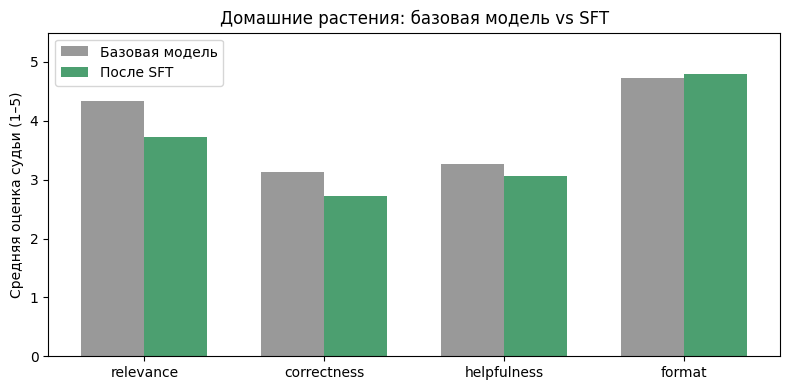

In [23]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(CRITERIA))
w = 0.35
ax.bar([i - w/2 for i in x], [summary["criteria"][c]["base"] for c in CRITERIA],
       w, label="Базовая модель", color="#999999")
ax.bar([i + w/2 for i in x], [summary["criteria"][c]["sft"] for c in CRITERIA],
       w, label="После SFT", color="#4c9f70")
ax.set_xticks(list(x)); ax.set_xticklabels(CRITERIA)
ax.set_ylim(0, 5.5); ax.set_ylabel("Средняя оценка судьи (1–5)")
ax.set_title("Домашние растения: базовая модель vs SFT")
ax.legend()
plt.tight_layout()
plt.savefig("outputs/metrics_plot.png", dpi=150)
plt.show()

## 7. Скачать артефакты

Архив с результатами для репозитория: адаптер (веса), данные, ответы моделей, метрики, график.

In [24]:
import shutil, zipfile
from pathlib import Path
from google.colab import files

shutil.make_archive("houseplants-lora", "zip", ".", "houseplants-lora")

# архив артефактов: метрики/ответы + данные для SFT (train.jsonl, seed, eval-вопросы)
with zipfile.ZipFile("houseplants-artifacts.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for d in ("outputs", "data"):
        for p in Path(d).rglob("*"):
            if p.is_file():
                z.write(p, p)

files.download("houseplants-lora.zip")
files.download("houseplants-artifacts.zip")
print("Скачаны: houseplants-lora.zip (веса), houseplants-artifacts.zip "
      "(метрики, ответы, данные для SFT)")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Скачаны: houseplants-lora.zip (веса), houseplants-artifacts.zip (метрики, ответы, данные для SFT)


In [25]:
from IPython.display import FileLink, display

print('Архивы:')
display(FileLink('houseplants-lora.zip'))
display(FileLink('houseplants-artifacts.zip'))

print('Ключевые файлы напрямую:')
display(FileLink('outputs/metrics.json'))
display(FileLink('outputs/metrics_plot.png'))
display(FileLink('outputs/judge_scores.json'))

Архивы:


/kaggle/working/houseplants-lora.zip

/kaggle/working/houseplants-artifacts.zip

Ключевые файлы напрямую:


/kaggle/working/outputs/metrics.json

/kaggle/working/outputs/metrics_plot.png

/kaggle/working/outputs/judge_scores.json

## Что дальше

1. Разложите `houseplants-artifacts.zip` в корень `project/` репозитория: `outputs/`
   (метрики, ответы, график) и `data/` (train.jsonl и пр.).
2. Числа из `outputs/metrics.json` и примеры ответов переносятся в `report.md`
   (места отмечены `[ЗАПОЛНИТЬ ПОСЛЕ ПРОГОНА]`).